<a href="https://colab.research.google.com/github/YazGonzalezHerrera/Simulaci-n-II/blob/main/Modelo%20SIR%20con%20Metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Modelo SIR: Ajuste de parámetros con Metropolis**

El articulo de investigación *The inverse problem of a dynamical system solved with genetic algorithms* (2021), presenta el siguiente problema:

En enero de 1978, tras las vacaciones de invierno, 763 estudiantes varones regresaron a su internado. Después de una semana, uno de los estudiantes contrajo gripe, luego dos más se enfermaron y así sucesivamente. Para finales de mes, casi la mitad de los estudiantes estaba enferma, la mayor parte de la escuela se había visto afectada y a mediados de febrero la epidemia habia terminado.

**Modelo SIR**

El modelo SIR consiste en un sistema de tres ecuaciones diferenciales ordinarias no lineales acopladas que no poseen una solución analítica explícita.

En este modelo, desarrollado por Ronald Ross, William Hamer y otros, una población se divide en 3 grupos:

1.   Susceptibles, $S=S(t)$
2.   Infectados, $I=I(t)$
3.   Recuperados, $R=R(t)$

Las ecuaciones dinámicas son las siguientes:

$\frac{dS}{dt} =  - aSI$

$\frac{dI}{dt} = aSI - bI$

$\frac{dR}{dt} = bI$

Donde $a$ es la tasa de transmisión y $b$ es la tasa promedio de recuperación.

En cualquier momento, la población total es $N=S+I+R$ y permanece constante, donde el punto superior implica derivada con respecto al tiempo $t$.

**Graficando los datos del problema**

Día,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
Infectados observados,1,3,6,25,73,222,294,258,237,191,125,69,27,11,4


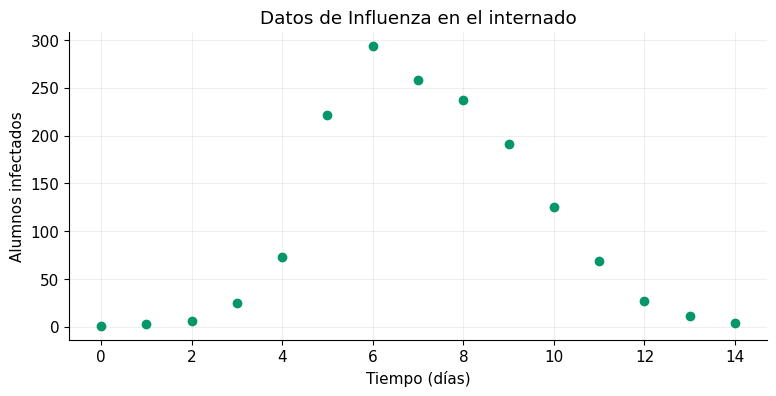

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint, solve_ivp, ODEintWarning

N = 763.0
Y0 = np.array([762.0, 1.0, 0.0])  # Compartimentos: S, I, R
t_obs = np.arange(15, dtype=float)
i_obs = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4], dtype=float)

display(pd.DataFrame({"Día": t_obs.astype(int), "Infectados observados": i_obs.astype(int)}).T.style.hide(axis="columns"))

fig, ax = plt.subplots()
ax.scatter(t_obs, i_obs, color=COLORES[2], zorder=3)
ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados", title="Datos de Influenza en el internado")
ax.grid(alpha=.2)
plt.show()

Al principio, $S(t)$ es aproximadamente igual a $N$ y $I(t)$ es muy pequeño. En el brote, $I(t)$ aumentará cada día hasta alcanzar un máximo y luego tenderá a disminuir lentamente como se muestra en el gráfico.

**Mínimos cuadrados**

Para poder plantear un ajuste de los parámetros $(a,b)$ podemos tomar el método de minimos cuadrados para obtener $X(a,b)$.

In [13]:
from scipy.optimize import minimize
from scipy.integrate import solve_ivp
import numpy as np

# Datos anteriores
t_data = np.array(list(range(15)))
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# Función de Suma de Errores Cuadráticos (SSE)
def sse_func(params):
    a_val, b_val = params

    def model(t, y):
        S, I, R = y
        return [-a_val * S * I, a_val * S * I - b_val * I, b_val * I]

    # Resolver la EDO con los parámetros candidatos
    sol = solve_ivp(model, (0, 14), [762, 1, 0], t_eval=t_data)

    # Calcular residuo cuadrático sobre I(t)
    if sol.success:
        I_pred = sol.y[1]
        return np.sum((I_data - I_pred)**2)
    return 1e10

# Optimización por mínimos cuadrados
initial_guess = [0.00218, 0.4485]
res = minimize(sse_func, initial_guess, bounds=[(1e-5, 1), (1e-5, 1)])
a_ls, b_ls = res.x

print(f"Parámetros por el método de mínimos cuadrados:")
print(f"a = {a_ls:.6f}, b = {b_ls:.6f}")

Parámetros por el método de mínimos cuadrados:
a = 0.002180, b = 0.445534


Con este método se probaron diferentes valores iniciales para $(a,b)$ calculando una simulación del modelo. En cada intento, se midió la diferencia mediante la Suma de Errores Cuadráticos (SSE), entre los infectados reales del internado y los que predijo el modelo. Los valores mostrados para $a$ y $b$ son los que lograron minimizar ese error al máximo, para que la curva imite el comportamiento real de la epidemia.

**Curva del comportamiento de los datos con $a$ y $b$ mediante minimos cuadrados**

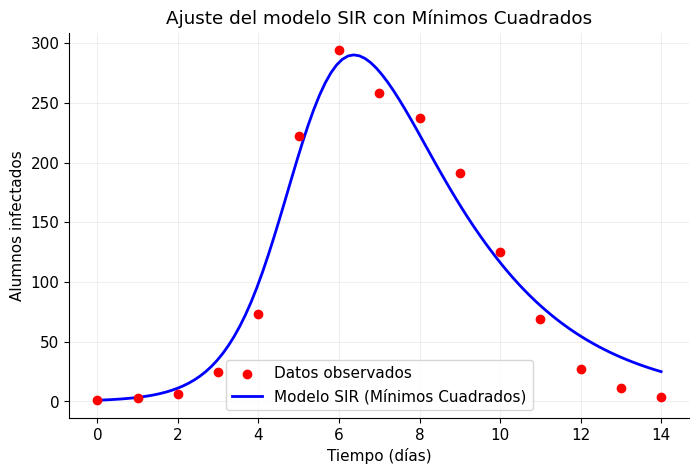

In [16]:
# Tiempo en la curva
t_curve = np.linspace(0, 14, 100)

# Método de mínimos cuadrados
def model_opt(t, y):
    S, I, R = y
    return [-a_ls * S * I, a_ls * S * I - b_ls * I, b_ls * I]

# Resolver la EDO con los parámetros óptimos
sol_opt = solve_ivp(model_opt, (0, 14), [762.0, 1.0, 0.0], t_eval=t_curve)

# Gráfica de los datos reales y mínimos cuadrados
fig, ax = plt.subplots(figsize=(8, 5))

# Puntos reales observados
ax.scatter(t_obs, i_obs, color='red', label='Datos observados', zorder=3)

# Curva teórica del modelo SIR
ax.plot(sol_opt.t, sol_opt.y[1], color='blue', linewidth=2, label='Modelo SIR (Mínimos Cuadrados)')
ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados", title="Ajuste del modelo SIR con Mínimos Cuadrados")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**Optimizar con Metropolis-Hastings**

Ahora, podemos intentar optimizar los puntos $a$ y $b$ mediante el modelo Metropolis-Hastings.

In [18]:
def log_likelihood(params):
    a_val, b_val = params
    if a_val <= 0 or b_val <= 0:
        return -np.inf

    def model(t, y):
        S, I, R = y
        return [-a_val * S * I, a_val * S * I - b_val * I, b_val * I]

    sol = solve_ivp(model, (0, 14), [762, 1, 0], t_eval=t_data)
    if not sol.success:
        return -np.inf

    I_pred = sol.y[1]
    sigma = 10.0  # Desviación estimada de los errores
    return -0.5 * np.sum(((I_data - I_pred) / sigma)**2)

# Metropolis-Hastings
num_samples = 5000
chain_params = np.zeros((num_samples, 2))
current = np.array([0.002, 0.4])
chain_params[0] = current

for t in range(1, num_samples):
    proposal = current + np.random.normal(0, [0.00005, 0.005])
    log_alpha = log_likelihood(proposal) - log_likelihood(current)

    if np.log(np.random.uniform(0, 1)) < log_alpha:
        current = proposal

    chain_params[t] = current

burn_in_sir = 1000
a_mcmc = np.mean(chain_params[burn_in_sir:, 0])
b_mcmc = np.mean(chain_params[burn_in_sir:, 1])

print(f"Parámetros estimados mediante Metropolis-Hastings:")
print(f"a = {a_mcmc:.6f}, b = {b_mcmc:.6f}")

Parámetros estimados mediante Metropolis-Hastings:
a = 0.002181, b = 0.445980


A diferencia de mínimos cuadrados que dan un único valor determinista, estos valores representan la media de las muestras aceptadas después de explorar el espacio de probabilidad con 5,000 iteraciones.

**Curva del comportamiento de los datos con $a$ y $b$ mediante Metropolis-Hastings**

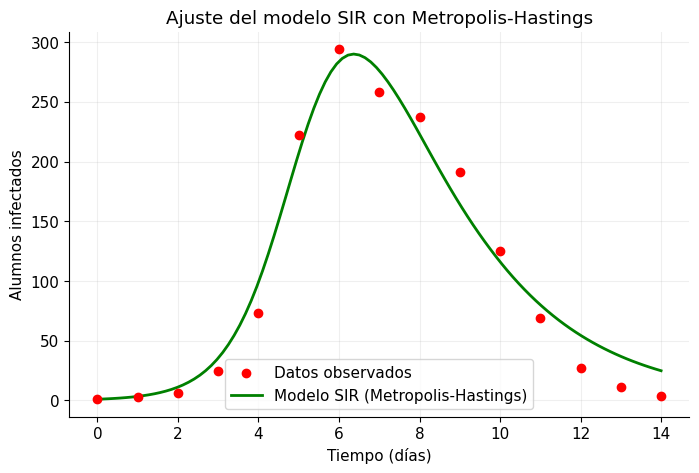

In [19]:
# Tiempo en la curva para una línea suave
t_curve = np.linspace(0, 14, 100)

# Modelo SIR usando los parámetros estimados por MCMC
def model_mcmc(t, y):
    S, I, R = y
    return [-a_mcmc * S * I, a_mcmc * S * I - b_mcmc * I, b_mcmc * I]

# Resolver la EDO con los parámetros de Metropolis-Hastings
sol_mcmc = solve_ivp(model_mcmc, (0, 14), [762.0, 1.0, 0.0], t_eval=t_curve)

# Gráfica de comparación
fig, ax = plt.subplots(figsize=(8, 5))

# Puntos reales observados
ax.scatter(t_obs, i_obs, color='red', label='Datos observados', zorder=3)

# Curva teórica del modelo SIR con MCMC
ax.plot(sol_mcmc.t, sol_mcmc.y[1], color='green', linewidth=2, label='Modelo SIR (Metropolis-Hastings)')

ax.set(xlabel="Tiempo (días)", ylabel="Alumnos infectados", title="Ajuste del modelo SIR con Metropolis-Hastings")
ax.grid(alpha=0.2)
ax.legend()
plt.show()

**Conclusión**

Si comparamos ambas gráficas, podemos notar que son practicamente idénticas a simple vista, al graficar las dos curvas de los modelos sobre los puntos rojos de los datos observados, las lineas se superpondrian casi por completo. Esto ocurre porque los parámetros obtenidos por ambos métodos son sumamente cercanos.

La diferencia radica en que la gráfica por mínimos cuadrados nos muestra una solución única y determinista, y la curva por Metropolis-Hastings está respaldada por las miles de iteraciones probabilísticas por Monte Carlo, lo que significa que no es solo una linea, sino que detrás de ella hay un análisis de incertidumbre que permite evaluar la probabilidad de otros escenarios de contagio y recuperación.